# Packed-bed model

`PackedBedModel` describes a bed of spherical PCM capsules with the heat transfer fluid
flowing through the voids. At each point along the bed, heat conducts across a capsule
(resolved radially) and into the fluid at its surface. It is built from the same submodels
as the finned-tube models, so it has the same outputs, conserves energy exactly and runs the
same experiments.

The default parameters are the experiments of Nallusamy et al. (2007): a 47 l tank of
paraffin capsules in water, charged with water at 70 °C from 32 °C.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pybamm

import pytes

model = pytes.PackedBedModel()
model.print_submodel_info()

fluid: AdvectedFluid (Heat transfer fluid)
    requires:
        Heat transfer fluid heat gain per unit length [W.m-1]
        Initial uniform temperature [K]
    provides:
        Heat transfer fluid specific enthalpy [J.kg-1]
        Inlet specific enthalpy [J.kg-1]
        Outlet specific enthalpy [J.kg-1]
        Mass flow rate [kg.s-1]
        Heat transfer fluid thermal energy [J]
        Heat transfer fluid temperature [K]
        Inlet temperature [K]
        Outlet temperature [K]
    parameters:
        Bed cross-sectional area [m2]
        Bed porosity
        Heat transfer fluid density [kg.m-3]
        Heat transfer fluid specific heat capacity [J.kg-1.K-1]
        Inlet temperature [K]
        Mass flow rate [kg.s-1]
        PCM melting temperature [K]
        Reference temperature [K]
    assumptions:
        The fluid is incompressible, with constant density.
        Axial conduction and dispersion in the fluid are neglected.
        The flow is the same in every flow p

In [2]:
t_end = 160 * 60
solution = pybamm.Simulation(model).solve(
    [0, t_end], t_interp=np.linspace(0, t_end, 321)
)
E = solution["Total thermal energy [J]"].entries
discharged = solution["Discharged energy [J]"].entries
print("max conservation error [J]:", np.max(np.abs(E - E[0] + discharged)))
print("stored energy [kWh]:", E[-1] / 3.6e6)
print(
    "energy between 32 and 70 degC [kWh]:",
    pytes.energy_between(model, 273.15 + 32, 273.15 + 70) / 3.6e6,
)
print(
    "stored energy per unit area [MJ.m-2]:",
    solution["Total thermal energy per unit area [J.m-2]"].entries[-1] / 1e6,
)

max conservation error [J]: 4.377216100692749e-08
stored energy [kWh]: 2.3031769907288466
energy between 32 and 70 degC [kWh]: 2.635389843901675
stored energy per unit area [MJ.m-2]: 81.45822286444718


The measured fluid temperatures at a quarter, half, three quarters and the full height
of the bed (points) against the model (lines).

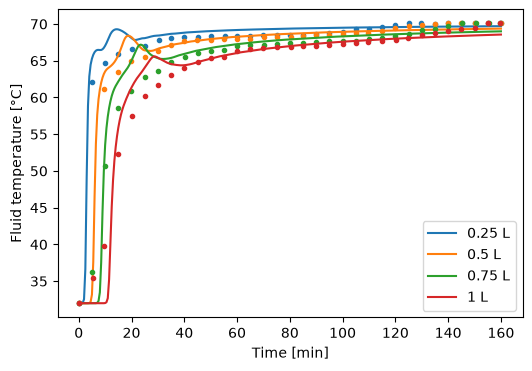

In [3]:
Z = model.default_parameter_values["Bed length [m]"]
fig, ax = plt.subplots(figsize=(6, 4))
for position, fraction in [("0.25L", 0.25), ("0.5L", 0.5), ("0.75L", 0.75), ("1L", 1)]:
    t_data, T_data = np.loadtxt(
        f"data/Nallusamy2007_HTF_{position}.csv", delimiter=",", skiprows=1, unpack=True
    )
    t = solution["Time [s]"].entries
    T = solution["Heat transfer fluid temperature [degC]"](t=t, z=fraction * Z)
    (line,) = ax.plot(t / 60, T, label=f"{fraction:g} L")
    ax.plot(t_data, T_data, "o", color=line.get_color(), markersize=3)
ax.set_xlabel("Time [min]")
ax.set_ylabel("Fluid temperature [°C]")
ax.legend()
plt.show()

The fluid temperatures agree with the measurements to 1 K to 2 K (root mean square).
Inside the capsules the agreement is looser, about 5 K at 0.8 of the capsule radius, which
depends on where the thermocouples sat and on the capsule shell, which the model neglects.

With `options={"storage along flow path": "averaged"}`, one capsule stands for the average along the bed and
exchanges heat with the fluid averaged along it: much faster, but it cannot capture the
thermal front moving through the bed. Every model has this option.

Note the dip of the averaged outlet below the initial 32 °C early on: the heat the capsule
takes from the averaged fluid is taken uniformly along the bed, including near the outlet,
where the fluid is still cold. This is a known artefact of this formulation, the published reduced
model; energy is still conserved exactly.

solve time: resolved 1.645 s, averaged 73.224 ms


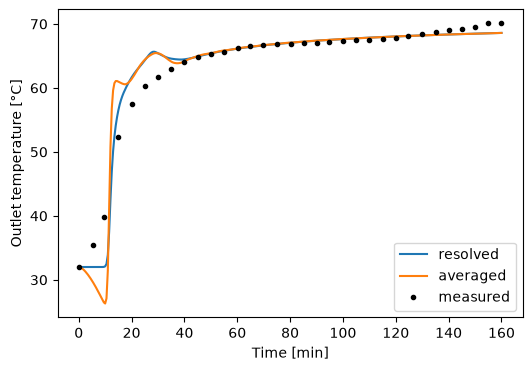

In [4]:
averaged = pytes.PackedBedModel(options={"storage along flow path": "averaged"})
averaged_solution = pybamm.Simulation(averaged).solve(
    [0, t_end], t_interp=np.linspace(0, t_end, 321)
)
print(
    f"solve time: resolved {solution.solve_time}, averaged {averaged_solution.solve_time}"
)

t_data, T_data = np.loadtxt(
    "data/Nallusamy2007_HTF_1L.csv", delimiter=",", skiprows=1, unpack=True
)
fig, ax = plt.subplots(figsize=(6, 4))
for sol, label in [(solution, "resolved"), (averaged_solution, "averaged")]:
    ax.plot(
        sol["Time [min]"].entries, sol["Outlet temperature [degC]"].entries, label=label
    )
ax.plot(t_data, T_data, "ko", markersize=3, label="measured")
ax.set_xlabel("Time [min]")
ax.set_ylabel("Outlet temperature [°C]")
ax.legend()
plt.show()